In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('qbank.csv')

In [3]:
df.head()

,item_id,content,options,correct_answer,question_type,topic,cognitive_level,a,b,c
0,1,What is the primary activation function used i...,A) Sigmoid; B) ReLU; C) Tanh; D) Softmax,A,MCQ-Single,ANN,Knowledge,1.2,-0.5,0.20
1,2,Which technique is used to prevent overfitting...,A) Increasing learning rate; B) Dropout; C) Ad...,B,MCQ-Single,ANN,Knowledge,1.5,-0.2,0.10
2,3,"In a CNN, what is the main purpose of a poolin...",A) To add non-linearity; B) To perform classif...,C,MCQ-Single,CNN,Knowledge,1.8,0.1,0.20
3,4,Which of these is NOT a common layer type in a...,A) Convolutional Layer; B) Recurrent Layer; C)...,B,MCQ-Single,CNN,Knowledge,1.3,-1.0,0.25
4,5,Which algorithm is a classic example of a line...,A) Decision Tree; B) K-Nearest Neighbors; C) L...,C,MCQ-Single,Linear Models,Knowledge,1.0,-1.5,0.20


In [4]:
df['topic'].value_counts()

topic
ANN                11
Statistics         10
MLOps               9
CNN                 8
Ensemble Models     8
Linear Models       4
Name: count, dtype: int64

In [9]:
df['cognitive_level'].value_counts()

cognitive_level
Knowledge      21
Application    16
Analysis       13
Name: count, dtype: int64

In [16]:
df['question_type'].value_counts()

question_type
MCQ-Single      39
MCQ-Multiple    11
Name: count, dtype: int64

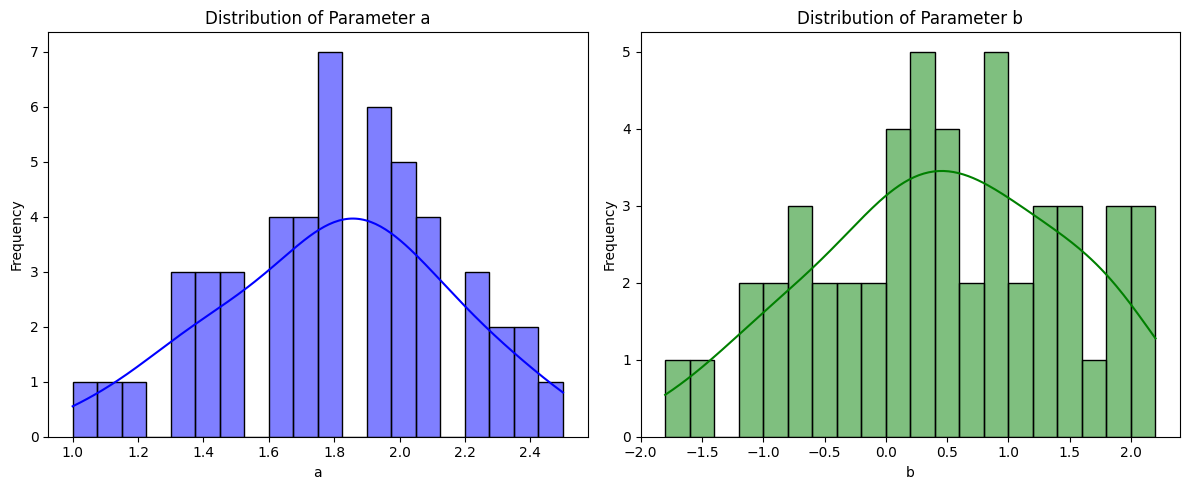

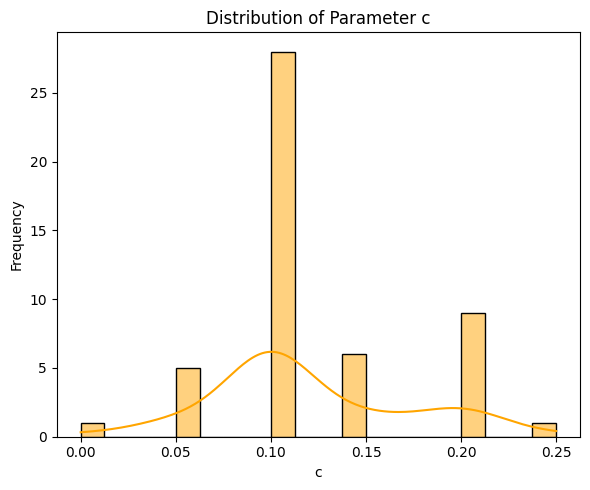

In [ ]:
# Visualizations histrograms with a, b and c parameters
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['a'], bins=20, kde=True, color='blue')
plt.title('Distribution of Parameter a')
plt.xlabel('a')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
sns.histplot(df['b'], bins=20, kde=True, color='green')
plt.title('Distribution of Parameter b')
plt.xlabel('b')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
sns.histplot(df['c'], bins=20, kde=True, color='orange')
plt.title('Distribution of Parameter c')
plt.xlabel('c')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()




In [15]:
df['a'].max(), df['a'].min()

(2.5, 1.0)

In [1]:
import pandas as pd

# Read the original qbank
df = pd.read_csv('qbank.csv')

# Define all possible dimensions based on the unique values in the CSV
all_topics = ['ANN', 'CNN', 'Ensemble Models', 'Linear Models', 'MLOps', 'Statistics']
all_cognitive_levels = ['Knowledge', 'Application', 'Analysis']
all_dimensions = ['General'] + all_topics + all_cognitive_levels

# Initialize a new DataFrame for the Q-matrix. Start with the item_id.
q_matrix_df = pd.DataFrame()
q_matrix_df['item_id'] = df['item_id']

# Add the original parameters that we need to keep
q_matrix_df['a'] = df['a']
q_matrix_df['b'] = df['b']
q_matrix_df['c'] = df['c']

# --- Create the new dimension columns ---
# 1. The 'General' factor: Every item gets a 1 here.
q_matrix_df['General'] = 1

# 2. Topic Dimensions: For each topic, check if the item's topic matches.
for topic in all_topics:
    q_matrix_df[topic] = (df['topic'] == topic).astype(int)

# 3. Cognitive Level Dimensions: For each level, check if the item's cognitive_level matches.
for level in all_cognitive_levels:
    q_matrix_df[level] = (df['cognitive_level'] == level).astype(int)

# Reorder columns to have a logical structure: ID, then all dimensions, then parameters
final_columns = ['item_id'] + all_dimensions + ['a', 'b', 'c']
q_matrix_df = q_matrix_df[final_columns]

# Save the new multidimensional item bank to a CSV file
output_filename = 'multidimensional_qbank.csv'
q_matrix_df.to_csv(output_filename, index=False)

print(f"Conversion complete! New file saved as: {output_filename}")
print(f"\nNew file structure preview:")
print(q_matrix_df.head())
print(f"\nNew shape: {q_matrix_df.shape}")

Conversion complete! New file saved as: multidimensional_qbank.csv

New file structure preview:
   item_id  General  ANN  CNN  Ensemble Models  Linear Models  MLOps  \
0        1        1    1    0                0              0      0   
1        2        1    1    0                0              0      0   
2        3        1    0    1                0              0      0   
3        4        1    0    1                0              0      0   
4        5        1    0    0                0              1      0   

   Statistics  Knowledge  Application  Analysis    a    b     c  
0           0          1            0         0  1.2 -0.5  0.20  
1           0          1            0         0  1.5 -0.2  0.10  
2           0          1            0         0  1.8  0.1  0.20  
3           0          1            0         0  1.3 -1.0  0.25  
4           0          1            0         0  1.0 -1.5  0.20  

New shape: (50, 14)


In [ ]:
script to generate mulitdimensional_qbank.csv

# Define all possible dimensions based on the unique values in the CSV
all_topics = ['ANN', 'CNN', 'Ensemble Models', 'Linear Models', 'MLOps', 'Statistics']
all_cognitive_levels = ['Knowledge', 'Application', 'Analysis']
all_dimensions = ['General'] + all_topics + all_cognitive_levels

# Initialize a new DataFrame for the Q-matrix. Start with the item_id.
q_matrix_df = pd.DataFrame()
q_matrix_df['item_id'] = df['item_id']

# Add the original parameters that we need to keep
q_matrix_df['a'] = df['a']
q_matrix_df['b'] = df['b']
q_matrix_df['c'] = df['c']

# --- Create the new dimension columns ---
# 1. The 'General' factor: Every item gets a 1 here.
q_matrix_df['General'] = 1

# 2. Topic Dimensions: For each topic, check if the item's topic matches.
for topic in all_topics:
    q_matrix_df[topic] = (df['topic'] == topic).astype(int)

# 3. Cognitive Level Dimensions: For each level, check if the item's cognitive_level matches.
for level in all_cognitive_levels:
    q_matrix_df[level] = (df['cognitive_level'] == level).astype(int)

# Reorder columns to have a logical structure: ID, then all dimensions, then parameters
final_columns = ['item_id'] + all_dimensions + ['a', 'b', 'c']
q_matrix_df = q_matrix_df[final_columns]